# Model building & Evalutaion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set_style('whitegrid')

import warnings
warnings.filterwarnings('ignore')


In [4]:
df = pd.read_csv('data/clean_aqi_features.csv', parse_dates=['date'])
df

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,...,quarter,dayofyear,is_weekend,lag_1,lag_24,roll_d,roll_w,wind_NW,wind_SE,wind_cv
0,193,2010,1,9,0,165.0,-17,-13.0,1027.0,0.89,...,1,9,1,169.0,210.0,176.208333,85.744048,0,0,1
1,194,2010,1,9,1,159.0,-17,-13.0,1027.0,3.13,...,1,9,1,165.0,195.0,174.333333,85.958333,1,0,0
2,195,2010,1,9,2,167.0,-17,-14.0,1027.0,4.92,...,1,9,1,159.0,275.0,172.833333,86.023810,1,0,0
3,196,2010,1,9,3,196.0,-17,-15.0,1027.0,8.05,...,1,9,1,167.0,164.0,168.333333,86.071429,1,0,0
4,197,2010,1,9,4,169.0,-17,-13.0,1027.0,9.84,...,1,9,1,196.0,110.0,169.666667,86.160714,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22909,43820,2014,12,31,19,8.0,-23,-2.0,1034.0,231.97,...,4,365,0,10.0,35.0,12.416667,121.476190,1,0,0
22910,43821,2014,12,31,20,10.0,-22,-3.0,1034.0,237.78,...,4,365,0,8.0,26.0,11.291667,121.404762,1,0,0
22911,43822,2014,12,31,21,10.0,-22,-3.0,1034.0,242.70,...,4,365,0,10.0,20.0,10.625000,121.327381,1,0,0
22912,43823,2014,12,31,22,8.0,-22,-4.0,1034.0,246.72,...,4,365,0,10.0,8.0,10.208333,121.291667,1,0,0


## train/test split and scaling

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [8]:
wind_cols = [c for c in df.columns if c.startswith('wind_')]
feature_cols = ['hour','dayofweek','month','quarter','year','dayofyear','is_weekend',
                'DEWP','TEMP','PRES','Iws','Is','Ir',
                'lag_1','lag_24','roll_d','roll_w'] + wind_cols

X = df[feature_cols]
y = df['pm2.5']

X_train, X_test,y_train, y_test = train_test_split(X, y, test_size=.2)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f'Train: {X_train.shape}   Test: {X_test.shape}')
print(f'Train period: {df["date"].iloc[0].date()} → {df["date"].iloc[split_idx-1].date()}')
print(f'Test  period: {df["date"].iloc[split_idx].date()} → {df["date"].iloc[-1].date()}')
print('\nTarget stats (train):')
print(y_train.describe().round(2))

Train: (18331, 20)   Test: (4583, 20)
Train period: 2010-01-09 → 2014-02-03
Test  period: 2014-02-03 → 2014-12-31

Target stats (train):
count    18331.00
mean        95.82
std         89.78
min          1.00
25%         27.00
50%         69.00
75%        135.00
max        700.00
Name: pm2.5, dtype: float64


## Training regressors

In [21]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score, TimeSeriesSplit
from sklearn.metrics import r2_score

In [14]:
from utils import evaluate_model, plot_predictions, plot_residuals, cross_validate_model, compare_models

In [12]:
results = []
models  = {}  # name → (kind, fitted_model)

### i. Linear Regression


  Linear Regression
  MAE   : 12.9170
  RMSE  : 24.2044
  R2    : 0.9319
  MAPE  : 0.2306


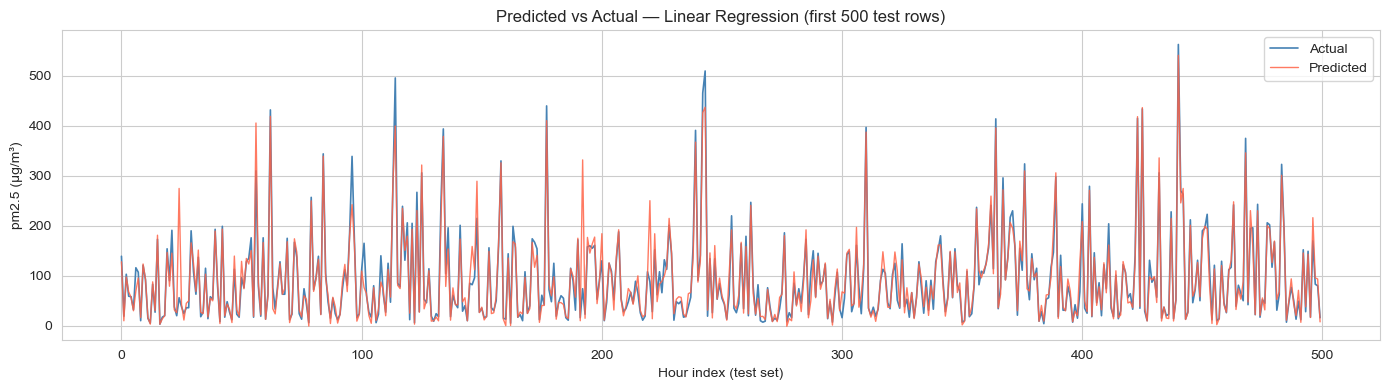

In [15]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)
results.append(evaluate_model('Linear Regression', y_test, y_pred))
models['Linear Regression'] = ('scaled', lr)
plot_predictions(y_test.values, y_pred, 'Linear Regression')
plt.show()

### ii. Ridge Regression


  Ridge
  MAE   : 12.9173
  RMSE  : 24.2042
  R2    : 0.9319
  MAPE  : 0.2306


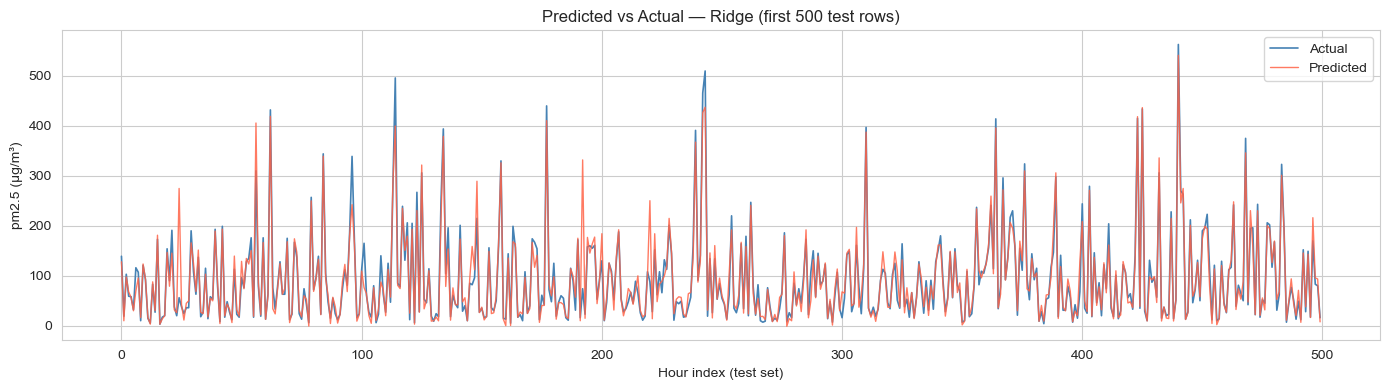

In [16]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred = ridge.predict(X_test_scaled)
results.append(evaluate_model('Ridge', y_test, y_pred))
models['Ridge'] = ('scaled', ridge)
plot_predictions(y_test.values, y_pred, 'Ridge')
plt.show()

### iii. Lasso Regression


  Lasso
  MAE   : 12.8472
  RMSE  : 24.2019
  R2    : 0.9319
  MAPE  : 0.2265


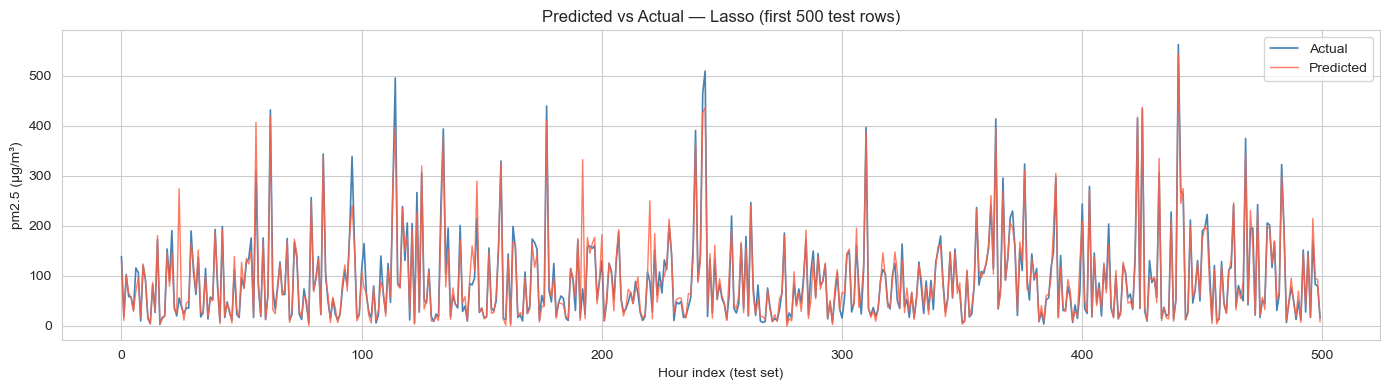

In [17]:
lasso = Lasso(alpha=0.1, max_iter=10000)
lasso.fit(X_train_scaled, y_train)
y_pred = lasso.predict(X_test_scaled)
results.append(evaluate_model('Lasso', y_test, y_pred))
models['Lasso'] = ('scaled', lasso)
plot_predictions(y_test.values, y_pred, 'Lasso')
plt.show()

### iv. Decision Tree


  Decision Tree
  MAE   : 14.1492
  RMSE  : 28.1073
  R2    : 0.9082
  MAPE  : 0.2284


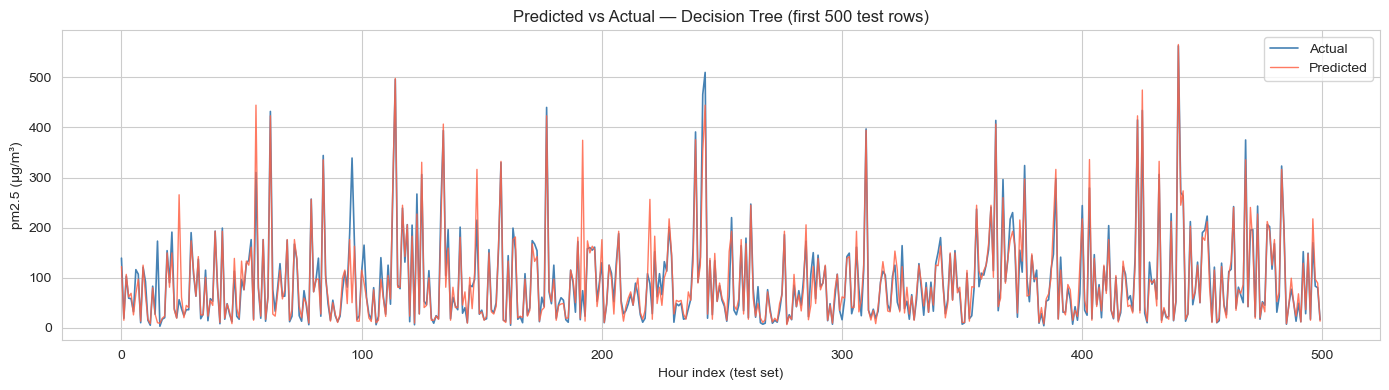

In [18]:
dt = DecisionTreeRegressor(max_depth=10)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
results.append(evaluate_model('Decision Tree', y_test, y_pred))
models['Decision Tree'] = ('raw', dt)
plot_predictions(y_test.values, y_pred, 'Decision Tree')
plt.show()

### v. Random Forest


  Random Forest
  MAE   : 12.9363
  RMSE  : 24.8891
  R2    : 0.9280
  MAPE  : 0.2176


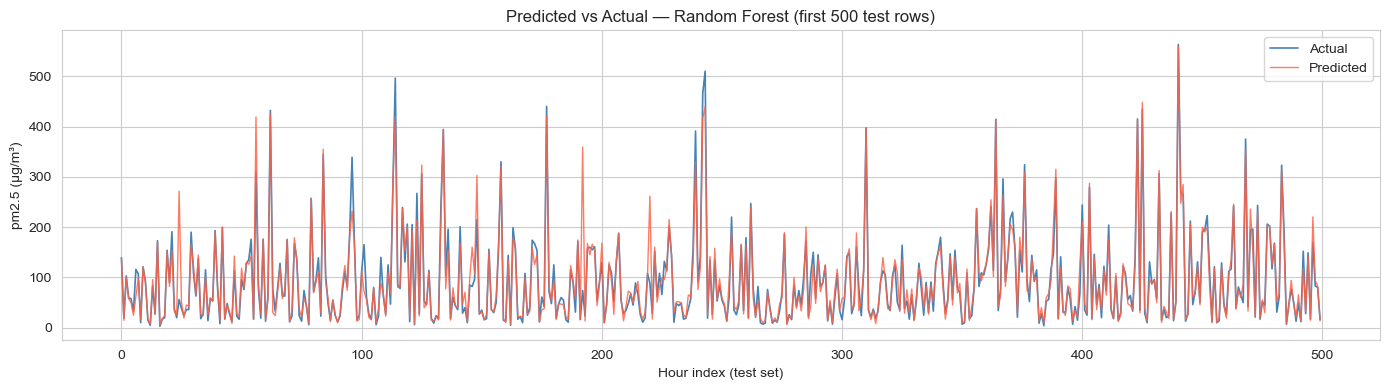

In [19]:
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
results.append(evaluate_model('Random Forest', y_test, y_pred))
models['Random Forest'] = ('raw', rf)
plot_predictions(y_test.values, y_pred, 'Random Forest')
plt.show()

### vi. KNN

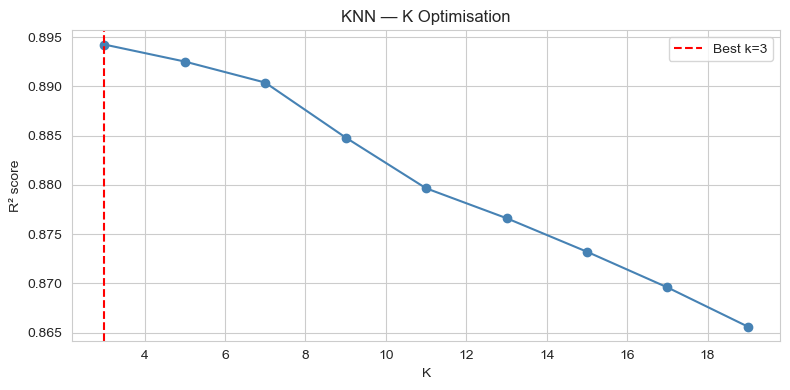


  KNN (k=3)
  MAE   : 17.0652
  RMSE  : 30.1604
  R2    : 0.8942
  MAPE  : 0.2998


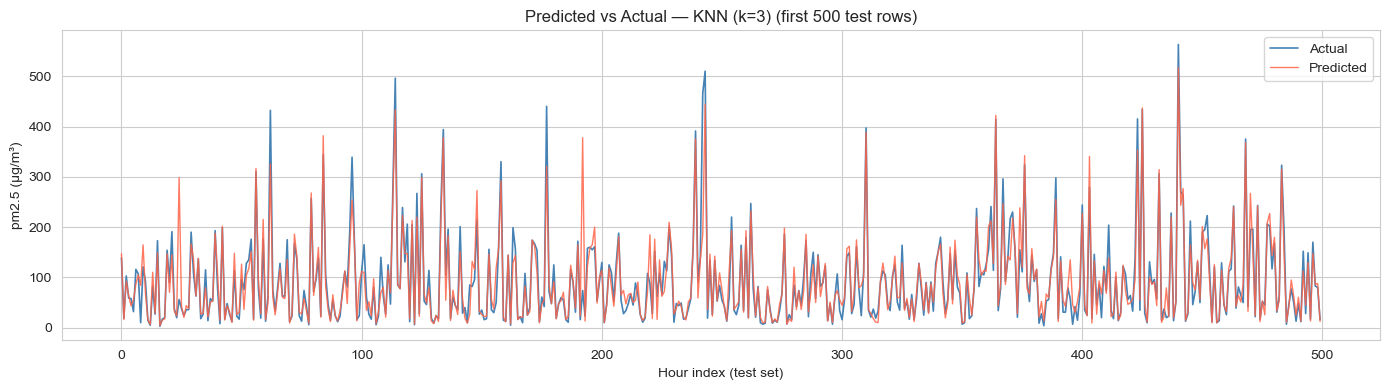

In [22]:
k_range = range(3, 20, 2)
k_scores = []
for k in k_range:
    knn_t = KNeighborsRegressor(n_neighbors=k, n_jobs=-1)
    knn_t.fit(X_train_scaled, y_train)
    k_scores.append(r2_score(y_test, knn_t.predict(X_test_scaled)))

best_k = list(k_range)[int(np.argmax(k_scores))]

plt.figure(figsize=(8, 4))
plt.plot(list(k_range), k_scores, marker='o', color='steelblue')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('K'); plt.ylabel('R² score'); plt.title('KNN — K Optimisation')
plt.legend(); plt.tight_layout(); plt.show()

knn = KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
knn_label = f'KNN (k={best_k})'
results.append(evaluate_model(knn_label, y_test, y_pred))
models[knn_label] = ('scaled', knn)
plot_predictions(y_test.values, y_pred, knn_label)
plt.show()

### vii. Gradient Boosting


  Gradient Boosting
  MAE   : 12.5442
  RMSE  : 24.2994
  R2    : 0.9314
  MAPE  : 0.2131


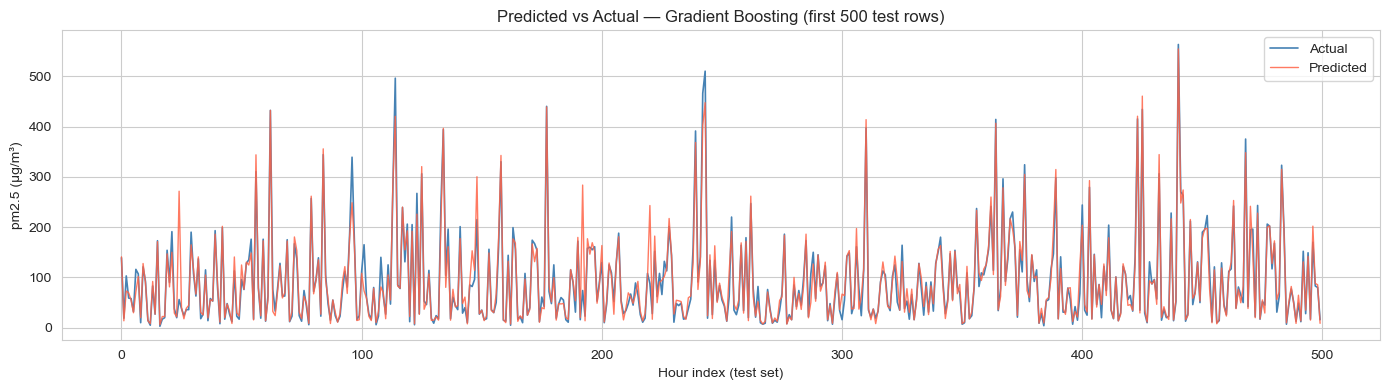

In [23]:
gb = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1,
                                max_depth=5)
gb.fit(X_train, y_train)
y_pred = gb.predict(X_test)
results.append(evaluate_model('Gradient Boosting', y_test, y_pred))
models['Gradient Boosting'] = ('raw', gb)
plot_predictions(y_test.values, y_pred, 'Gradient Boosting')
plt.show()

## Model Comparision

In [24]:
comparison = compare_models(results)
print(comparison.to_string(index=False))

            Model       MAE      RMSE       R2     MAPE
            Lasso 12.847158 24.201947 0.931903 0.226490
            Ridge 12.917309 24.204178 0.931890 0.230636
Linear Regression 12.917039 24.204367 0.931889 0.230637
Gradient Boosting 12.544225 24.299393 0.931353 0.213126
    Random Forest 12.936260 24.889110 0.927981 0.217648
    Decision Tree 14.149232 28.107258 0.908153 0.228393
        KNN (k=3) 17.065241 30.160381 0.894244 0.299766


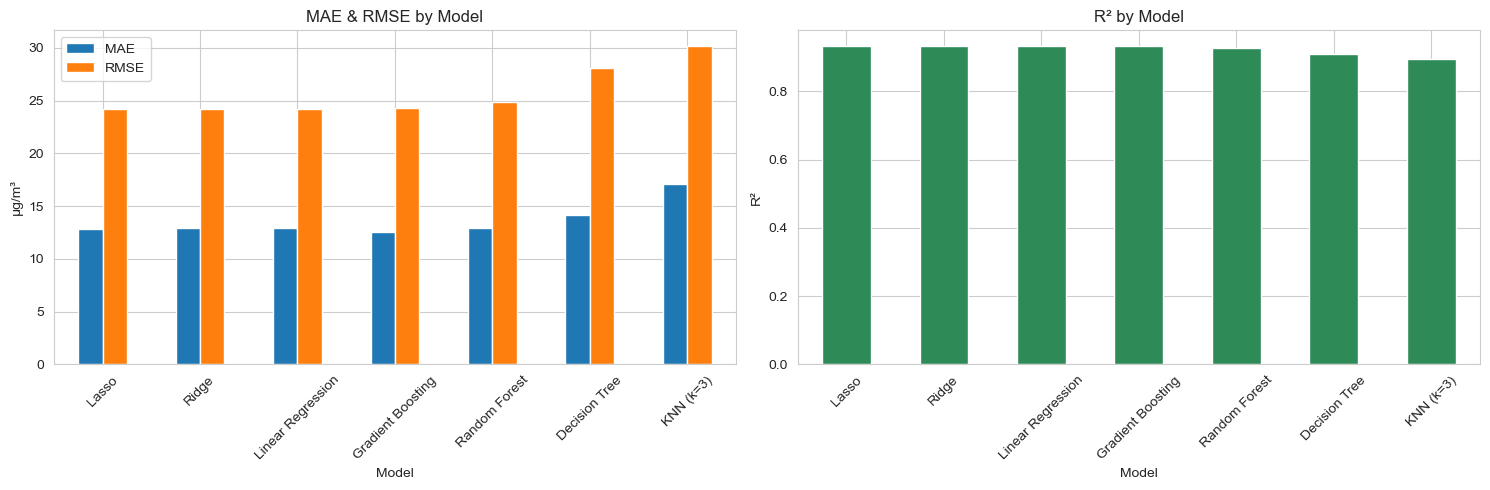

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comparison.set_index('Model')[['MAE', 'RMSE']].plot(kind='bar', ax=axes[0])
axes[0].set_title('MAE & RMSE by Model'); axes[0].set_ylabel('µg/m³')
axes[0].tick_params(axis='x', rotation=45)
comparison.set_index('Model')['R2'].plot(kind='bar', color='seagreen', ax=axes[1])
axes[1].set_title('R² by Model'); axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

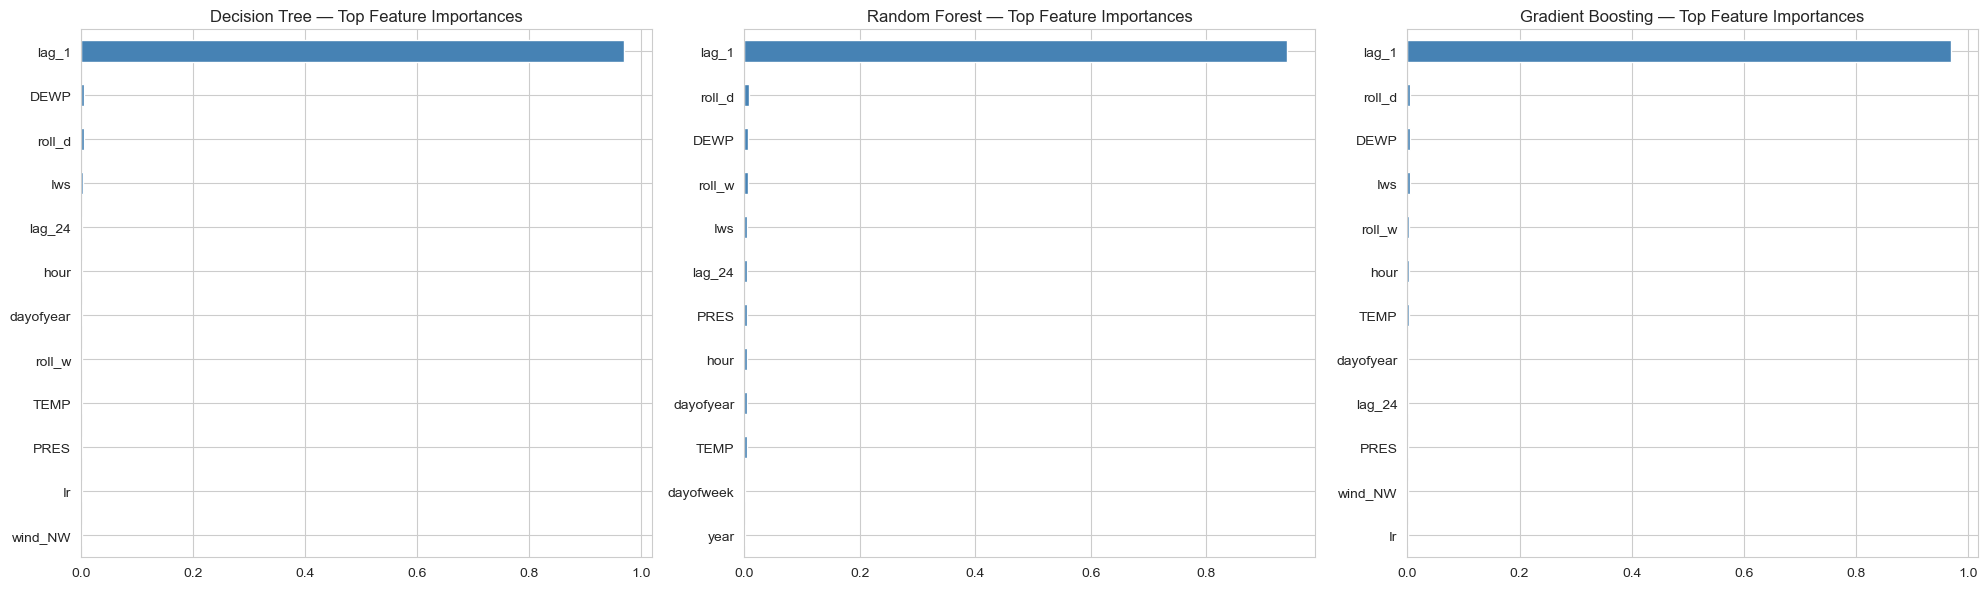

In [26]:
tree_models = [('Decision Tree', dt), ('Random Forest', rf), ('Gradient Boosting', gb)]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, model) in zip(axes, tree_models):
    imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values().tail(12)
    imp.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'{name} — Top Feature Importances')
plt.tight_layout(); plt.show()

## Time Series Cross Validation

In [27]:
tscv = TimeSeriesSplit(n_splits=5)
cv_scores = {}

cv_candidates = {
    'Linear Regression': ('scaled', lr),
    'Ridge':             ('scaled', ridge),
    'Decision Tree':     ('raw',    dt),
    'Random Forest':     ('raw',    rf),
    'Gradient Boosting': ('raw',    gb),
}

X_full_scaled = scaler.fit_transform(X)

for name, (kind, model) in cv_candidates.items():
    Xuse = X_full_scaled if kind == 'scaled' else X
    scores = cross_val_score(model, Xuse, y, cv=tscv, scoring='r2', n_jobs=-1)
    cv_scores[name] = scores
    print(f'{name:25s}  mean R² = {scores.mean():.4f}  (+/- {scores.std():.4f})')

Linear Regression          mean R² = 0.9383  (+/- 0.0067)
Ridge                      mean R² = 0.9383  (+/- 0.0066)
Decision Tree              mean R² = 0.8796  (+/- 0.0433)
Random Forest              mean R² = 0.9228  (+/- 0.0080)
Gradient Boosting          mean R² = 0.8949  (+/- 0.0590)


## Hyperparameter Tuning (Best Model)

In [28]:
best_model_name = comparison.iloc[0]['Model']
print(f'Best model: {best_model_name}')

base_name = best_model_name.split(' (k=')[0] if 'KNN' in best_model_name else best_model_name
kind_best, best_obj = models[best_model_name]

if 'Random Forest' in base_name:
    param_grid = {'n_estimators': [200, 300], 'max_depth': [None, 20], 'min_samples_leaf': [1, 2]}
    tuner_model = RandomForestRegressor(random_state=42, n_jobs=-1)
    use_scaled = False
elif 'Gradient Boosting' in base_name:
    param_grid = {'n_estimators': [150, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [4, 5]}
    tuner_model = GradientBoostingRegressor(random_state=42)
    use_scaled = False
elif 'Decision Tree' in base_name:
    param_grid = {'max_depth': [8, 10, 15], 'min_samples_leaf': [1, 2, 5]}
    tuner_model = DecisionTreeRegressor(random_state=42)
    use_scaled = False
elif 'KNN' in base_name:
    param_grid = {'n_neighbors': [3, 5, 7, 9]}
    tuner_model = KNeighborsRegressor(n_jobs=-1)
    use_scaled = True
elif 'Ridge' in base_name:
    param_grid = {'alpha': [0.1, 1.0, 10.0, 100.0]}
    tuner_model = Ridge()
    use_scaled = True
else:
    param_grid = {'alpha': [0.01, 0.1, 1.0]}
    tuner_model = Lasso(max_iter=10000)
    use_scaled = True

Xtr_g = X_train_scaled if use_scaled else X_train
Xte_g = X_test_scaled  if use_scaled else X_test

grid = GridSearchCV(tuner_model, param_grid, cv=TimeSeriesSplit(n_splits=3),
                    scoring='r2', n_jobs=-1, verbose=0)
grid.fit(Xtr_g, y_train)
print('Best params:', grid.best_params_)
print('Best CV R²:', round(grid.best_score_, 4))

best_tuned = grid.best_estimator_
y_pred_tuned = best_tuned.predict(Xte_g)
tuned_label = f'{base_name} (Tuned)'
tuned_metrics = evaluate_model(tuned_label, y_test, y_pred_tuned)
results.append(tuned_metrics)

Best model: Lasso
Best params: {'alpha': 0.01}
Best CV R²: 0.9352

  Lasso (Tuned)
  MAE   : 12.9018
  RMSE  : 24.1981
  R2    : 0.9319
  MAPE  : 0.2298


## Residuals - tuned model

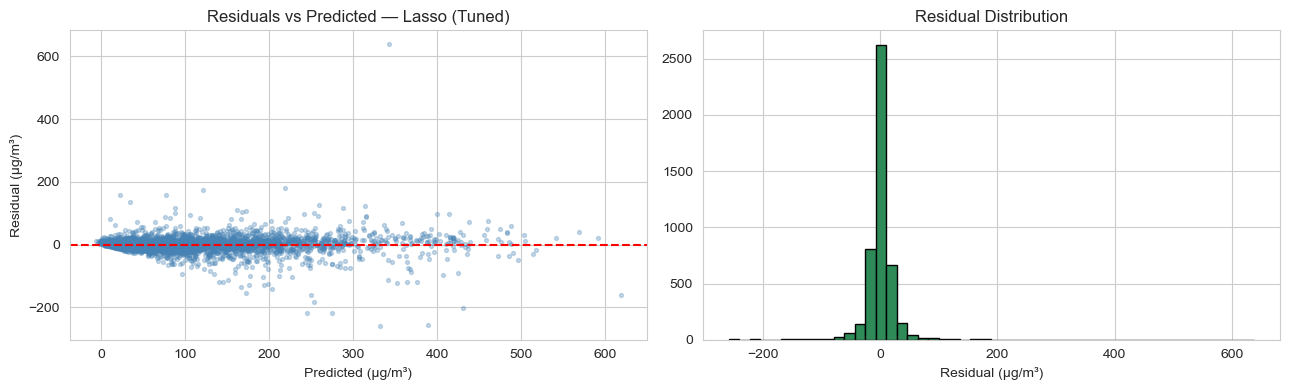

In [29]:
plot_residuals(y_test.values, y_pred_tuned, tuned_label)
plt.show()

# Example Prediction

In [31]:
n_sample = 10
sample_X = Xte_g[-n_sample:] if isinstance(Xte_g, np.ndarray) else Xte_g.iloc[-n_sample:]
sample_preds = best_tuned.predict(sample_X)
sample_actual = y_test.values[-n_sample:]

pred_df = pd.DataFrame({
    'date': df['date'].iloc[split_idx:].values[-n_sample:],
    'Actual':    sample_actual.round(1),
    'Predicted': sample_preds.round(1),
    'AbsError':  np.abs(sample_actual - sample_preds).round(1),
})
pred_df

,date,Actual,Predicted,AbsError
0,2014-12-31 14:00:00,15.0,16.4,1.4
1,2014-12-31 15:00:00,13.0,12.1,0.9
2,2014-12-31 16:00:00,255.0,256.6,1.6
3,2014-12-31 17:00:00,13.0,17.4,4.4
4,2014-12-31 18:00:00,16.0,23.6,7.6
5,2014-12-31 19:00:00,13.0,12.4,0.6
6,2014-12-31 20:00:00,87.0,78.8,8.2
7,2014-12-31 21:00:00,92.0,97.7,5.7
8,2014-12-31 22:00:00,62.0,77.4,15.4
9,2014-12-31 23:00:00,269.0,306.8,37.8


# Summary

In [32]:
final = compare_models(results)
print(final.to_string(index=False))

            Model       MAE      RMSE       R2     MAPE
    Lasso (Tuned) 12.901773 24.198073 0.931924 0.229778
            Lasso 12.847158 24.201947 0.931903 0.226490
            Ridge 12.917309 24.204178 0.931890 0.230636
Linear Regression 12.917039 24.204367 0.931889 0.230637
Gradient Boosting 12.544225 24.299393 0.931353 0.213126
    Random Forest 12.936260 24.889110 0.927981 0.217648
    Decision Tree 14.149232 28.107258 0.908153 0.228393
        KNN (k=3) 17.065241 30.160381 0.894244 0.299766
